<h1 style="color: #FF5733;">Pandas</h1>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Pandas -> Used for Data Manupulation and Data Analysis
# It provides two main data structures:
# Series -> One Dimensional Array
# DataFrame -> Two Dimensional Array

# Series

## Series From Lists

In [7]:
# String ~ (Object)
country = ['India', 'USA', 'Canada', 'Australia', 'Russia']
pd.Series(country)

0        India
1          USA
2       Canada
3    Australia
4       Russia
dtype: object

In [8]:
# Integers
runs = [100, 200, 300, 400, 500]
pd.Series(runs)

0    100
1    200
2    300
3    400
4    500
dtype: int64

In [9]:
# Custom Index
marks = [100, 200, 300, 400, 500]
students = ['A', 'B', 'C', 'D', 'E']
pd.Series(marks, index=students)

A    100
B    200
C    300
D    400
E    500
dtype: int64

In [12]:
# Settings a name
marks = pd.Series(marks, index=students, name='Marks')
marks

A    100
B    200
C    300
D    400
E    500
Name: Marks, dtype: int64

## Series From Dict

In [17]:
marks = {
    'A': 100,
    'B': 200,
    'C': 300,
    'D': 400,
    'E': 500
}
marks_series = pd.Series(marks, name='Marks')
marks_series

A    100
B    200
C    300
D    400
E    500
Name: Marks, dtype: int64

## Series Attributes

In [18]:
# Size
marks_series.size

5

In [19]:
# dtype
marks_series.dtype

dtype('int64')

In [20]:
# name
marks_series.name

'Marks'

In [28]:
# is_unique
print(marks_series.is_unique)
pd.Series([1, 1, 2, 3, 4, 5]).is_unique

True


False

In [ ]:
# Index
marks_series.index

Index(['A', 'B', 'C', 'D', 'E'], dtype='object')

In [32]:
# Values
marks_series.values

array([100, 200, 300, 400, 500], dtype=int64)

<h1 style="color: #FFC0CB;">Series Using read_csv</h1>

In [19]:
# With 1 column (Will not work with multiple columns 2+)

# Reading exel file instead of CSV for convenience
df = pd.read_excel('Pandas_learn.xlsx', engine='openpyxl')

# File Is Always Read As DataFrame -> Converting into Series using squeeze()

# Squeeze the DataFrame to a Series if possible
series = df.squeeze()
print(series)

0    975
1    984
2    165
3    615
4    165
5    852
Name: Subscriber Gained, dtype: int64


In [60]:
# With 2 columns

# Convert one column to index, then convert to Series

abc = pd.read_csv('D:\Machine Learning Notes\Pandas\B_energy_data.csv.csv', index_col=0) 
series = abc.squeeze()
print(series)

Outdoor Temperature (°C)
22.8    11822
33.6    10992
18.6     7999
22.8    11822
32.1    13857
15.8     6478
22.8     8815
20.2    14896
Name: Building Area (sq ft), dtype: int64


## Series Methods

In [52]:
# Head and Tail

abc = pd.read_csv('D:\Machine Learning Notes\Pandas\B_energy_data.csv.csv')
abc.head()

,Outdoor Temperature (°C),Building Area (sq ft)
0,22.8,11822
1,33.6,10992
2,18.6,7999
3,22.8,11822
4,32.1,13857


In [53]:
abc.tail(3)

,Outdoor Temperature (°C),Building Area (sq ft)
5,15.8,6478
6,22.8,8815
7,20.2,14896


In [54]:
# Sample(Random)
abc.sample(3)

,Outdoor Temperature (°C),Building Area (sq ft)
7,20.2,14896
3,22.8,11822
4,32.1,13857


In [55]:
# value_counts() -> Returns the count of unique values
abc.value_counts()

Outdoor Temperature (°C)  Building Area (sq ft)
22.8                      11822                    2
15.8                      6478                     1
18.6                      7999                     1
20.2                      14896                    1
22.8                      8815                     1
32.1                      13857                    1
33.6                      10992                    1
Name: count, dtype: int64

In [ ]:
# Sort values (It's Not Permanent)
# Sort values by a specific column 
sorted_abc = abc.sort_values(by='Building Area (sq ft)', ascending=True) # False -> descending
print(sorted_abc)

                          Building Area (sq ft)
Outdoor Temperature (°C)                       
15.8                                       6478
18.6                                       7999
22.8                                       8815
33.6                                      10992
22.8                                      11822
22.8                                      11822
32.1                                      13857
20.2                                      14896


In [ ]:
# Get the first value after sorting
top_value = sorted_abc.head(1)
print(top_value)

                          Building Area (sq ft)
Outdoor Temperature (°C)                       
15.8                                       6478


In [ ]:
# Print only the value
top_value = sorted_abc.head(1).values[0]
print(top_value)

[6478]


In [85]:
# Sort values Parmanently
abc.sort_values(by='Building Area (sq ft)', ascending=True, inplace=True)
print(abc)

                          Building Area (sq ft)
Outdoor Temperature (°C)                       
15.8                                       6478
18.6                                       7999
22.8                                       8815
33.6                                      10992
22.8                                      11822
22.8                                      11822
32.1                                      13857
20.2                                      14896


In [87]:
# Sort index
abc.sort_index(ascending=False, inplace=True)
print(abc)

                          Building Area (sq ft)
Outdoor Temperature (°C)                       
33.6                                      10992
32.1                                      13857
22.8                                       8815
22.8                                      11822
22.8                                      11822
20.2                                      14896
18.6                                       7999
15.8                                       6478


In [88]:
abc.count()

Building Area (sq ft)    8
dtype: int64

In [89]:
abc.sum()

Building Area (sq ft)    86681
dtype: int64

In [90]:
abc.product()

Building Area (sq ft)    790216110458591232
dtype: int64

In [91]:
abc.mean()

Building Area (sq ft)    10835.125
dtype: float64

In [92]:
abc.median()

Building Area (sq ft)    11407.0
dtype: float64

In [93]:
abc.mode()

,Building Area (sq ft)
0,11822


In [94]:
abc.describe()

,Building Area (sq ft)
count,8.000000
mean,10835.125000
std,2895.906887
min,6478.000000
25%,8611.000000
50%,11407.000000
75%,12330.750000
max,14896.000000


In [95]:
abc.var()

Building Area (sq ft)    8.386277e+06
dtype: float64

## Series Indexing (Slicing)

In [116]:
# Integer as Index
x = pd.Series([10, 20, 30, 40, 50], index=[1, 2, 3, 4, 5])
print(x)

1    10
2    20
3    30
4    40
5    50
dtype: int64


In [117]:
# Integer Indexing
print(x[1])

10


In [118]:
# Negative Indexing -----> Does not work here.
# print(x[-1]) -> KeyError: -1 

In [111]:
# String as Indexing
x = pd.Series([10, 20, 30, 40, 50], index=['A', 'B', 'C', 'D', 'E'])
print(x)

A    10
B    20
C    30
D    40
E    50
dtype: int64


In [112]:
# It corrently works with string index
print(x['A'])
print(x[1])
print(x[-2])

10
20
40


C:\Users\piyus\AppData\Local\Temp\ipykernel_16632\510577160.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(x[1])
C:\Users\piyus\AppData\Local\Temp\ipykernel_16632\510577160.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(x[-2])


In [113]:
# Slicing
print(x['A':'C'])

A    10
B    20
C    30
dtype: int64


In [114]:
# Negative Slicing 
print(x[-3:])

C    30
D    40
E    50
dtype: int64


In [115]:
print(x[: : 2])

A    10
C    30
E    50
dtype: int64


In [116]:
# Fancy Indexing 
print(x[['A', 'C', 'E']])
print(x[[0, 2, 4]])

A    10
C    30
E    50
dtype: int64
A    10
C    30
E    50
dtype: int64


C:\Users\piyus\AppData\Local\Temp\ipykernel_16632\2859750746.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(x[[0, 2, 4]])


## Editing Series

In [117]:
x

A    10
B    20
C    30
D    40
E    50
dtype: int64

In [118]:
# Using Indexing
x['A'] = 100
x

A    100
B     20
C     30
D     40
E     50
dtype: int64

In [119]:
# What if an index does not exist
x['F'] = 200
x

A    100
B     20
C     30
D     40
E     50
F    200
dtype: int64

In [120]:
# Slicing
x['A':'C'] = 300
x

A    300
B    300
C    300
D     40
E     50
F    200
dtype: int64

In [121]:
# Fancy Indexing
x[['A', 'C', 'E']] = [400, 400, 40000]
x

A      400
B      300
C      400
D       40
E    40000
F      200
dtype: int64

## Series With Python Functionalities

In [27]:
ABC = pd.Series([1, 2, 3, 4, 5], index=['A', 'B', 'C', 'D', 'E'])

In [13]:
# len/type/dir/sorted/max/min
print(len(ABC))
print(type(ABC))
print(dir(ABC))  # -> all the methods that can be used with the object
print(sorted(ABC))
print(max(ABC))
print(min(ABC))

5
<class 'pandas.core.series.Series'>
['A', 'B', 'C', 'D', 'E', 'T', '_AXIS_LEN', '_AXIS_ORDERS', '_AXIS_TO_AXIS_NUMBER', '_HANDLED_TYPES', '__abs__', '__add__', '__and__', '__annotations__', '__array__', '__array_priority__', '__array_ufunc__', '__bool__', '__class__', '__column_consortium_standard__', '__contains__', '__copy__', '__deepcopy__', '__delattr__', '__delitem__', '__dict__', '__dir__', '__divmod__', '__doc__', '__eq__', '__finalize__', '__float__', '__floordiv__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__iadd__', '__iand__', '__ifloordiv__', '__imod__', '__imul__', '__init__', '__init_subclass__', '__int__', '__invert__', '__ior__', '__ipow__', '__isub__', '__iter__', '__itruediv__', '__ixor__', '__le__', '__len__', '__lt__', '__matmul__', '__mod__', '__module__', '__mul__', '__ne__', '__neg__', '__new__', '__nonzero__', '__or__', '__pandas_priority__', '__pos__', '__pow__', '__radd__', '__rand__', '

In [16]:
# type conversion
print(list(ABC))
print(dict(ABC))
print(set(ABC))

[1, 2, 3, 4, 5]
{'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5}
{1, 2, 3, 4, 5}


In [30]:
# membership operator - (Check if a Index is present in the object)
print('B' in ABC)
# membership operator - (Check if a Index is present in the object)
print(2 in ABC.values)

True
True


In [34]:
# looping - Runs on values
for i in ABC:
    print(i)

print()

# looping - To Run on Index    
for i in ABC.index:
    print(i)

1
2
3
4
5

A
B
C
D
E


In [36]:
# Arithmetic Operators (Broadcasting)
ABC + 10

A    11
B    12
C    13
D    14
E    15
dtype: int64

In [37]:
# Relational Operators
ABC > 3

A    False
B    False
C    False
D     True
E     True
dtype: bool

## Boolean Indexing On Series

In [40]:
# Find no of 50's and 100's in the series
ABC = pd.Series([10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
print(ABC[ABC >= 50].count())

6


In [42]:
# Count no of day when I had more than 200 subs a day
subs = pd.Series([100, 150, 200, 250, 300, 350, 400, 450, 500])
print(subs[subs > 200].size)

6


In [53]:
# Find actors with more than 20 movies (list of actor with movies)
movies = pd.Series([10, 20, 30, 40, 50, 10], index=['A', 'B', 'C', 'D', 'E', 'F'])
num_movies = movies.value_counts()
print(num_movies) 
print(num_movies >= 2)
print(num_movies[num_movies >= 2])

10    2
20    1
30    1
40    1
50    1
Name: count, dtype: int64
10     True
20    False
30    False
40    False
50    False
Name: count, dtype: bool
10    2
Name: count, dtype: int64


## Plotting Graph On Series

<Axes: >

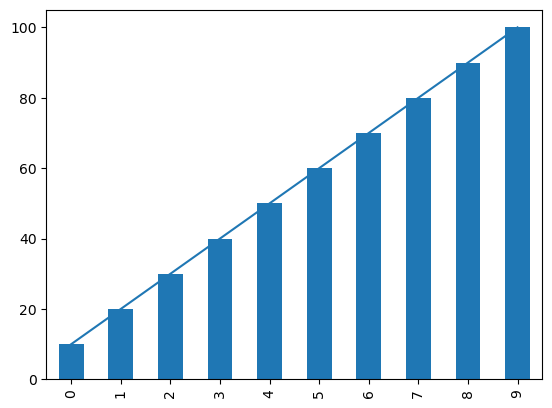

In [58]:
ABC.plot()
ABC.plot(kind='bar')

<Axes: >

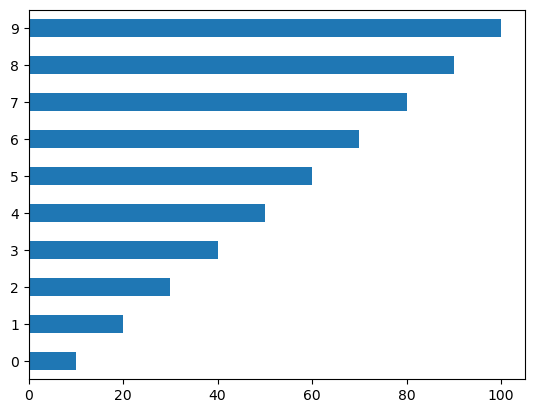

In [59]:
ABC.plot(kind='barh')

<Axes: >

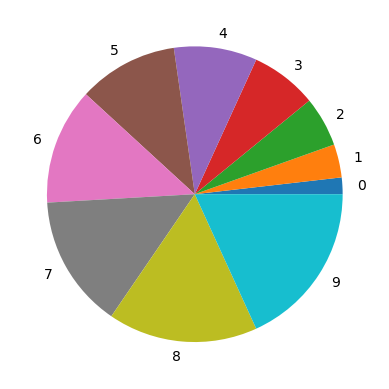

In [60]:
ABC.plot(kind='pie')

<Axes: >

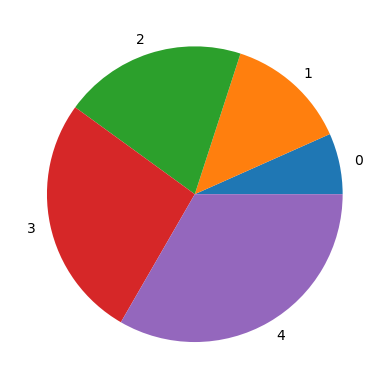

In [61]:
ABC.head(5).plot(kind='pie')

## Some Important Series Method

In [72]:
# astype
import sys
print(sys.getsizeof(ABC))
print(sys.getsizeof(ABC.astype('int8')))
print(sys.getsizeof(ABC.astype('int16')))

244
174
184


In [73]:
# between
print(ABC[ABC.between(20, 50)])

1    20
2    30
3    40
4    50
dtype: int64


In [74]:
# clip
ABC.clip(40, 50)

0    40
1    40
2    40
3    40
4    50
5    50
6    50
7    50
8    50
9    50
dtype: int64

In [80]:
# drop_duplicates (default keep='first')
print(ABC.drop_duplicates(keep='last'))
# For Checking if there are duplicates
print(ABC.duplicated().sum())

0     10
1     20
2     30
3     40
4     50
5     60
6     70
7     80
8     90
9    100
dtype: int64
0


In [87]:
# isnull
ABC = pd.Series([10, 20, 30, 40, 50, np.nan, 70, 80, 90, np.nan])
print(ABC.size)
print(ABC.count())
print(ABC.isnull().sum())

10
8
2


In [85]:
# dropna
print(ABC.dropna())

0    10.0
1    20.0
2    30.0
3    40.0
4    50.0
6    70.0
7    80.0
8    90.0
dtype: float64


In [89]:
# fillna
print(ABC.fillna(0))

0    10.0
1    20.0
2    30.0
3    40.0
4    50.0
5     0.0
6    70.0
7    80.0
8    90.0
9     0.0
dtype: float64


In [95]:
# isin

print(ABC[(ABC == 50) | (ABC == 70)])
# Better for Multiple Values
ABC[ABC.isin([50, 70])]


4    50.0
6    70.0
dtype: float64


4    50.0
6    70.0
dtype: float64

In [103]:
# apply (convert the float values to strings before applying the split() method.)

# ABC.apply(lambda x: x.split()[0].upper())
print(ABC.apply(lambda x: str(int(x)).split()[0].upper()if not pd.isnull(x) else x))

print(ABC.apply(lambda x: 'Good' if x > ABC.mean() else 'Bad'))

0     10
1     20
2     30
3     40
4     50
5    NaN
6     70
7     80
8     90
9    NaN
dtype: object
0     Bad
1     Bad
2     Bad
3     Bad
4    Good
5     Bad
6    Good
7    Good
8    Good
9     Bad
dtype: object


# Copy And Views

In [108]:
# head() and tail() gives the view of data not copy
# Any change in this changes the original

# copy (No change in original)
new = ABC.head().copy()
new[0] = 100
print(new)

0    100.0
1     20.0
2     30.0
3     40.0
4     50.0
dtype: float64


<h1 style="color:Purple;">DataFrame</h1>


In [122]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Creating DataFrame

In [123]:
# using lists (2D)
student_data = [
    ['A', 10, 20, 30],
    ['B', 20, 30, 40],
    ['C', 30, 40, 50],
    ['D', 40, 50, 60],
    ['E', 50, 60, 70]
]
pd.DataFrame(student_data, columns = ['Name', 'Maths', 'Physics', 'Chemistry'])

,Name,Maths,Physics,Chemistry
0,A,10,20,30
1,B,20,30,40
2,C,30,40,50
3,D,40,50,60
4,E,50,60,70


In [168]:
# using dicts
student_data = {
    'Name': ['A', 'B', 'C', 'D', 'E'],
    'Maths': [10, 20, 30, 40, 50],
    'Physics': [20, 30, 40, 50, 60],
    'Chemistry': [30, 40, 50, 60, 70]
}
stud = pd.DataFrame(student_data)
stud

,Name,Maths,Physics,Chemistry
0,A,10,20,30
1,B,20,30,40
2,C,30,40,50
3,D,40,50,60
4,E,50,60,70


In [129]:
# using read_csv
students = pd.read_csv('D:\Machine Learning Notes\Pandas\B_energy_data.csv.csv')
students

,Outdoor Temperature (°C),Building Area (sq ft)
0,22.8,11822
1,33.6,10992
2,18.6,7999
3,22.8,11822
4,32.1,13857
5,15.8,6478
6,22.8,8815
7,20.2,14896


## DataFrame Attributes And Methods

In [130]:
# shape
students.shape

(8, 2)

In [131]:
# dtypes
students.dtypes

Outdoor Temperature (°C)    float64
Building Area (sq ft)         int64
dtype: object

In [132]:
# index
students.index

RangeIndex(start=0, stop=8, step=1)

In [133]:
# columns
students.columns

Index(['Outdoor Temperature (°C)', 'Building Area (sq ft)'], dtype='object')

In [134]:
# values
students.values

array([[   22.8, 11822. ],
       [   33.6, 10992. ],
       [   18.6,  7999. ],
       [   22.8, 11822. ],
       [   32.1, 13857. ],
       [   15.8,  6478. ],
       [   22.8,  8815. ],
       [   20.2, 14896. ]])

In [137]:
# head and tail
print(students.head(2))
students.tail(2)

   Outdoor Temperature (°C)  Building Area (sq ft)
0                      22.8                  11822
1                      33.6                  10992


,Outdoor Temperature (°C),Building Area (sq ft)
6,22.8,8815
7,20.2,14896


In [ ]:
# sample 
students.sample(2)

,Outdoor Temperature (°C),Building Area (sq ft)
2,18.6,7999
4,32.1,13857


In [143]:
# info
students.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 2 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Outdoor Temperature (°C)  8 non-null      float64
 1   Building Area (sq ft)     8 non-null      int64  
dtypes: float64(1), int64(1)
memory usage: 260.0 bytes


In [144]:
# describe
students.describe()

,Outdoor Temperature (°C),Building Area (sq ft)
count,8.000000,8.000000
mean,23.587500,10835.125000
std,6.228606,2895.906887
min,15.800000,6478.000000
25%,19.800000,8611.000000
50%,22.800000,11407.000000
75%,25.125000,12330.750000
max,33.600000,14896.000000


In [149]:
# isnull
students.isnull().sum()

Outdoor Temperature (°C)    0
Building Area (sq ft)       0
dtype: int64

In [150]:
# duplicated
students.duplicated() # .sum() -> 1

0    False
1    False
2    False
3     True
4    False
5    False
6    False
7    False
dtype: bool

In [151]:
# rename
students.rename(columns = {'Building Area (sq ft)': 'Area'}, inplace=True)
students

,Outdoor Temperature (°C),Area
0,22.8,11822
1,33.6,10992
2,18.6,7999
3,22.8,11822
4,32.1,13857
5,15.8,6478
6,22.8,8815
7,20.2,14896


## Math Methods

In [ ]:
# sum
# axis 0 -> column wise (default)
# axis 1 -> row wise
students.sum(axis=0)


Outdoor Temperature (°C)      188.7
Area                        86681.0
dtype: float64

In [159]:
# mean
students.mean(axis=1)

0    5922.40
1    5512.80
2    4008.80
3    5922.40
4    6944.55
5    3246.90
6    4418.90
7    7458.10
dtype: float64

In [161]:
# min
students.min()

Outdoor Temperature (°C)      15.8
Area                        6478.0
dtype: float64

## Selecting Columns from DataFrame

In [165]:
# single column
print(students['Area'])
type(students['Area'])

0    11822
1    10992
2     7999
3    11822
4    13857
5     6478
6     8815
7    14896
Name: Area, dtype: int64


pandas.core.series.Series

In [167]:
# multi column
print(students[['Area', 'Outdoor Temperature (°C)']])

    Area  Outdoor Temperature (°C)
0  11822                      22.8
1  10992                      33.6
2   7999                      18.6
3  11822                      22.8
4  13857                      32.1
5   6478                      15.8
6   8815                      22.8
7  14896                      20.2


## Selecting Rows from DataFrame

In [170]:
# using dicts
student_data = {
    'Name': ['A', 'B', 'C', 'D', 'E'],
    'Maths': [10, 20, 30, 40, 50],
    'Physics': [20, 30, 40, 50, 60],
    'Chemistry': [30, 40, 50, 60, 70]
}
stud = pd.DataFrame(student_data)
stud.set_index('Name', inplace=True)
stud

,Maths,Physics,Chemistry
Name,,,
A,10,20,30
B,20,30,40
C,30,40,50
D,40,50,60
E,50,60,70


     -> iloc : searches using index position
     -> loc : search using index lables

In [174]:
# single row
print(students.iloc[0])

Outdoor Temperature (°C)       22.8
Area                        11822.0
Name: 0, dtype: float64


In [ ]:
# multiple rows
print(students.iloc[0:3])
print(students.iloc[[0, 2, 4]]) # Fancy Indexing

   Outdoor Temperature (°C)   Area
0                      22.8  11822
1                      33.6  10992
2                      18.6   7999
   Outdoor Temperature (°C)   Area
0                      22.8  11822
2                      18.6   7999
4                      32.1  13857


In [177]:
stud.loc['B']

Maths        20
Physics      30
Chemistry    40
Name: B, dtype: int64

In [179]:
# Range in iloc does not include last 
# Range in loc includes last
stud.loc['A':'C']

,Maths,Physics,Chemistry
Name,,,
A,10,20,30
B,20,30,40
C,30,40,50


In [181]:
# Can Also use iloc
stud.iloc[0:3]

,Maths,Physics,Chemistry
Name,,,
A,10,20,30
B,20,30,40
C,30,40,50


## Selecting Both Rows and Column

In [ ]:
## First 3 Column & 2 Rows
stud.iloc[0:2, 0:3]

,Maths,Physics,Chemistry
Name,,,
A,10,20,30
B,20,30,40


In [183]:
stud.loc['A':'C', 'Maths':'Physics']

,Maths,Physics
Name,,
A,10,20
B,20,30
C,30,40


## Filtering a DataFrame

In [188]:
# Printing Physics Marks for those who got 20 in Maths
new = stud['Maths'] == 20
new_st = stud[new]
new_st['Physics'] 


Name
B    30
Name: Physics, dtype: int64

In [189]:
# Same thing in one line
stud[stud['Maths'] == 20]['Physics']

Name
B    30
Name: Physics, dtype: int64

In [195]:
# shape[0] -> row
stud[stud['Maths'] == 20].shape[0]


1

In [203]:
# either maths 20 or physics 20
# Working with Binary
stud[(stud['Maths'] == 20) ^ (stud['Physics'] == 20)]

,Maths,Physics,Chemistry
Name,,,
A,10,20,30
B,20,30,40


In [216]:
# Percentage that if got math >= 20 then physics >= 20
# Normally if one condition use == 
# if 2 conditions use &
(stud[(stud['Maths'] >= 20) == (stud['Physics'] >= 20)].shape[0]/stud.shape[0])*100

80.0

In [217]:
# Action movies with rating higher than 7.5
movies = {
    'Name': ['A', 'B', 'C', 'D', 'E'],
    'Genre': ['Action/Comedy', 'Comedy', 'Horror/Action', 'Action', 'Comedy'],
    'Rating': [7.5, 8, 6, 8.5, 7]
}
movies = pd.DataFrame(movies)
movies

,Name,Genre,Rating
0,A,Action/Comedy,7.5
1,B,Comedy,8.0
2,C,Horror/Action,6.0
3,D,Action,8.5
4,E,Comedy,7.0


In [232]:
# Multiple Genre-> Can't Select Action alone
# Converting into string and splitting
cond1 = movies['Genre'].str.split('/').apply(lambda x: 'Action' in x)
cond1
# OR
# cond1 = movies['Genre'].str.contains('Action')

0     True
1    False
2     True
3     True
4    False
Name: Genre, dtype: bool

In [230]:
cond2 = movies['Rating'] >= 7.5
cond2

0     True
1     True
2    False
3     True
4    False
Name: Rating, dtype: bool

In [231]:
movies[cond1 & cond2]

,Name,Genre,Rating
0,A,Action/Comedy,7.5
3,D,Action,8.5


## Adding New Cols

In [234]:
# New Cols
movies['Country'] = ['USA', 'India', 'China', 'Russia', 'Japan']
movies

,Name,Genre,Rating,Country
0,A,Action/Comedy,7.5,USA
1,B,Comedy,8.0,India
2,C,Horror/Action,6.0,China
3,D,Action,8.5,Russia
4,E,Comedy,7.0,Japan


In [237]:
# 1st Gerene
movies['Genre'].str.split('/').str[0]
# Or
# movies['Genre'].str.split('/').apply(lambda x: x[0])

0    Action
1    Comedy
2    Horror
3    Action
4    Comedy
Name: Genre, dtype: object

## Important DataFrame Functions

In [249]:
# astype
movies.info()
print()
movies['Rating'] = movies['Rating'].astype('int32')
movies.info()
# Object -> Category (if it is a category)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Name     5 non-null      object
 1   Genre    5 non-null      object
 2   Rating   5 non-null      int64 
 3   Country  5 non-null      object
dtypes: int64(1), object(3)
memory usage: 292.0+ bytes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Name     5 non-null      object
 1   Genre    5 non-null      object
 2   Rating   5 non-null      int32 
 3   Country  5 non-null      object
dtypes: int32(1), object(3)
memory usage: 272.0+ bytes


In [239]:
# value_counts

In [238]:
# sort_values --> ascending --> na_position --> inplace --> multiple_cols

<h3 style="color: Pink;">Group By</h3>

In [3]:
import pandas as pd

In [81]:
movies = {
    'Name': ['A', 'B', 'C', 'D', 'E'],
    'Genre': ['Action/Comedy', 'Comedy', 'Horror/Action', 'Action', 'Comedy'],
    'Rating': [7.5, 8, 6, 8.5, 7],
    'Runtime': [100, 120, 90, 110, 130],
    'Income': [1000, 2000, 3000, 4000, 5000]
}
movies = pd.DataFrame(movies)
movies

,Name,Genre,Rating,Runtime,Income
0,A,Action/Comedy,7.5,100,1000
1,B,Comedy,8.0,120,2000
2,C,Horror/Action,6.0,90,3000
3,D,Action,8.5,110,4000
4,E,Comedy,7.0,130,5000


In [13]:
genere = movies.groupby('Genre')
genere.sum()

,Name,Rating,Runtime,Income
Genre,,,,
Action,D,8.5,110,4000
Action/Comedy,A,7.5,100,1000
Comedy,BE,15.0,250,7000
Horror/Action,C,6.0,90,3000


In [14]:
movies.groupby('Genre').sum()['Income'].sort_values(ascending=False).head(3)

Genre
Comedy           7000
Action           4000
Horror/Action    3000
Name: Income, dtype: int64

In [17]:
# Faster way (For Big Data)
movies.groupby('Genre')['Income'].sum().sort_values(ascending=False).head(3)

Genre
Comedy           7000
Action           4000
Horror/Action    3000
Name: Income, dtype: int64

In [19]:
# Genre with highest average rating
movies.groupby('Genre')['Rating'].mean().sort_values(ascending=False).head(1)

Genre
Action    8.5
Name: Rating, dtype: float64

## GroupBy Attributes and Methods

(Need Practice)

In [22]:
# find total number of groups -> len
len(movies.groupby('Genre'))
# or
movies['Genre'].nunique()

4

In [24]:
# find items in each groups -> size
movies.groupby('Genre').size() # sorted on index (prefered)
# or
# movies['Genre'].value_counts() # sorted on values

Genre
Action           1
Action/Comedy    1
Comedy           2
Horror/Action    1
dtype: int64

In [48]:
# first()/last() -> nth item
# movies.groupby('Genre').first()
# movies.groupby('Genre').last() -> last movie of each genre
movies.groupby('Genre').nth(1) # -> 2nd movie of each genre

,Name,Genre,Rating,Runtime,Income
4,E,Comedy,7.0,130,5000


In [ ]:
# get_group -> vs filtring
# movies.groupby('Genre').get_group('Action') --> Better
movies[movies['Genre'] == 'Action']

,Name,Genre,Rating,Runtime,Income
3,D,Action,8.5,110,4000


In [51]:
# groups
genere.groups

{'Action': [3], 'Action/Comedy': [0], 'Comedy': [1, 4], 'Horror/Action': [2]}

In [52]:
# describe
movies.groupby('Genre').describe()

Rating                                           Runtime         \
               count mean       std  min   25%  50%   75%  max   count   mean   
Genre                                                                           
Action           1.0  8.5       NaN  8.5  8.50  8.5  8.50  8.5     1.0  110.0   
Action/Comedy    1.0  7.5       NaN  7.5  7.50  7.5  7.50  7.5     1.0  100.0   
Comedy           2.0  7.5  0.707107  7.0  7.25  7.5  7.75  8.0     2.0  125.0   
Horror/Action    1.0  6.0       NaN  6.0  6.00  6.0  6.00  6.0     1.0   90.0   

               ...               Income                                       \
               ...    75%    max  count    mean          std     min     25%   
Genre          ...                                                             
Action         ...  110.0  110.0    1.0  4000.0          NaN  4000.0  4000.0   
Action/Comedy  ...  100.0  100.0    1.0  1000.0          NaN  1000.0  1000.0   
Comedy         ...  127.5  130.0    2.0  3500.0  2121.320344  2000.0  2750.0   
Horror/Action  ...   90.0   90.0    1.0  3000.0          NaN  3000.0  3000.0   

                                       
                  50%     75%     max  
Genre                                  
Action         4000.0  4000.0  4000.0  
Action/Comedy  1000.0  1000.0  1000.0  
Comedy         3500.0  4250.0  5000.0  
Horror/Action  3000.0  3000.0  3000.0  

[4 rows x 24 columns]

In [53]:
# sample
movies.groupby('Genre').sample(1)

,Name,Genre,Rating,Runtime,Income
3,D,Action,8.5,110,4000
0,A,Action/Comedy,7.5,100,1000
4,E,Comedy,7.0,130,5000
2,C,Horror/Action,6.0,90,3000


In [54]:
# nunique
movies.groupby('Genre').nunique()

,Name,Rating,Runtime,Income
Genre,,,,
Action,1,1,1,1
Action/Comedy,1,1,1,1
Comedy,2,2,2,2
Horror/Action,1,1,1,1


In [62]:
# agg method

# passing dict
movies.groupby('Genre').agg({
    'Rating': 'mean',
    'Income': 'sum'
})

,Rating,Income
Genre,,
Action,8.5,4000
Action/Comedy,7.5,1000
Comedy,7.5,7000
Horror/Action,6.0,3000


In [61]:
# passing list
print(movies.groupby('Genre').agg({'min', 'max'}))

              Name     Rating      Runtime      Income      
               max min    max  min     max  min    max   min
Genre                                                       
Action           D   D    8.5  8.5     110  110   4000  4000
Action/Comedy    A   A    7.5  7.5     100  100   1000  1000
Comedy           E   B    8.0  7.0     130  120   5000  2000
Horror/Action    C   C    6.0  6.0      90   90   3000  3000


In [ ]:
# Adding both the syntax 

In [65]:
# looping on groups (To solve different problems)
for name, group in movies.groupby('Genre'):
    print(name)
    print(group)
    print()

Action
  Name   Genre  Rating  Runtime  Income
3    D  Action     8.5      110    4000

Action/Comedy
  Name          Genre  Rating  Runtime  Income
0    A  Action/Comedy     7.5      100    1000

Comedy
  Name   Genre  Rating  Runtime  Income
1    B  Comedy     8.0      120    2000
4    E  Comedy     7.0      130    5000

Horror/Action
  Name          Genre  Rating  Runtime  Income
2    C  Horror/Action     6.0       90    3000



In [67]:
# split (apply) combine
# apply -> built in
movies = movies.groupby('Genre').apply(lambda x: x['Income'].sum())
movies

Genre
Action           4000
Action/Comedy    1000
Comedy           7000
Horror/Action    3000
dtype: int64

In [85]:
def rank_movies(group):
    group['genre_rank'] = group['Rating'].rank(ascending = False)
    return group
new = movies.groupby('Genre')
new.apply(rank_movies)

Name          Genre  Rating  Runtime  Income  genre_rank
Genre                                                                   
Action        3    D         Action     8.5      110    4000         1.0
Action/Comedy 0    A  Action/Comedy     7.5      100    1000         1.0
Comedy        1    B         Comedy     8.0      120    2000         1.0
              4    E         Comedy     7.0      130    5000         2.0
Horror/Action 2    C  Horror/Action     6.0       90    3000         1.0

In [89]:
# Normalized Rating Group Wise
def normalize(group):
    group['normalized_rating'] = (group['Rating'] - group['Rating'].min()) / (group['Rating'].max() - group['Rating'].min())
    return group
new = movies.groupby('Genre')
new.apply(normalize)

Name          Genre  Rating  Runtime  Income  \
Genre                                                          
Action        3    D         Action     8.5      110    4000   
Action/Comedy 0    A  Action/Comedy     7.5      100    1000   
Comedy        1    B         Comedy     8.0      120    2000   
              4    E         Comedy     7.0      130    5000   
Horror/Action 2    C  Horror/Action     6.0       90    3000   

                 normalized_rating  
Genre                               
Action        3                NaN  
Action/Comedy 0                NaN  
Comedy        1                1.0  
              4                0.0  
Horror/Action 2                NaN

## Merging, Joining & Concatenating

In [26]:
course = {
    'Name': ['A', 'B', 'C', 'D', 'E', 'F', 'G'],
    'Maths': [10, 20, 30, 40, 50, 60, 70],
    'Physics': [20, 30, 40, 50, 60, 70, 80],
    'Chemistry': [30, 40, 50, 60, 70, 80, 100]
}
course = pd.DataFrame(course)
print(course)
print()
student = {
    'Name': ['A', 'B', 'C', 'D', 'E'],
    'Partner': [1, 2, 3, 4, 5]
}
student = pd.DataFrame(student)
print(student)

  Name  Maths  Physics  Chemistry
0    A     10       20         30
1    B     20       30         40
2    C     30       40         50
3    D     40       50         60
4    E     50       60         70
5    F     60       70         80
6    G     70       80        100

  Name  Partner
0    A        1
1    B        2
2    C        3
3    D        4
4    E        5


In [27]:
# pd.concat
pd.concat([course, student], ignore_index=True)

,Name,Maths,Physics,Chemistry,Partner
0,A,10.0,20.0,30.0,NaN
1,B,20.0,30.0,40.0,NaN
2,C,30.0,40.0,50.0,NaN
3,D,40.0,50.0,60.0,NaN
4,E,50.0,60.0,70.0,NaN
5,F,60.0,70.0,80.0,NaN
6,G,70.0,80.0,100.0,NaN
7,A,NaN,NaN,NaN,1.0
8,B,NaN,NaN,NaN,2.0
9,C,NaN,NaN,NaN,3.0


In [28]:
# df.concat
pd.concat([course, student], axis=1)

,Name,Maths,Physics,Chemistry,Name,Partner
0,A,10,20,30,A,1.0
1,B,20,30,40,B,2.0
2,C,30,40,50,C,3.0
3,D,40,50,60,D,4.0
4,E,50,60,70,E,5.0
5,F,60,70,80,NaN,NaN
6,G,70,80,100,NaN,NaN


In [29]:
# MultiIndex
pd.concat([course, student], keys=['Course', 'Student'])


Name  Maths  Physics  Chemistry  Partner
Course  0    A   10.0     20.0       30.0      NaN
        1    B   20.0     30.0       40.0      NaN
        2    C   30.0     40.0       50.0      NaN
        3    D   40.0     50.0       60.0      NaN
        4    E   50.0     60.0       70.0      NaN
        5    F   60.0     70.0       80.0      NaN
        6    G   70.0     80.0      100.0      NaN
Student 0    A    NaN      NaN        NaN      1.0
        1    B    NaN      NaN        NaN      2.0
        2    C    NaN      NaN        NaN      3.0
        3    D    NaN      NaN        NaN      4.0
        4    E    NaN      NaN        NaN      5.0

In [35]:
# Merge
import pandas as pd

# Sample DataFrames
data1 = {
    'id': [1, 2, 3, 4],
    'name': ['Alice', 'Bob', 'Charlie', 'David']
}

data2 = {
    'id': [3, 4, 5, 6],
    'age': [24, 25, 23, 22]
}

df1 = pd.DataFrame(data1)
df2 = pd.DataFrame(data2)

print("DataFrame 1:")
print(df1)

print("\nDataFrame 2:")
print(df2)

DataFrame 1:
   id     name
0   1    Alice
1   2      Bob
2   3  Charlie
3   4    David

DataFrame 2:
   id  age
0   3   24
1   4   25
2   5   23
3   6   22


In [52]:
# Inner Join (Most Used & Default Join)
# Returns only the rows with matching values in both DataFrames.
inner_join = pd.merge(df1, df2, on='id', how='inner')
print("\nInner Join:")
inner_join


Inner Join:


,id,name,age
0,3,Charlie,24
1,4,David,25


In [46]:
# Alternate Code
df1.merge(df2, on='id', how='inner')

,id,name,age
0,3,Charlie,24
1,4,David,25


In [49]:
# Left Join
# Returns all rows from the left DataFrame and the matched rows from the right DataFrame.
left_join = pd.merge(df1, df2, on='id', how='left')
print("\nLeft Join:")
left_join


Left Join:


,id,name,age
0,1,Alice,NaN
1,2,Bob,NaN
2,3,Charlie,24.0
3,4,David,25.0


In [48]:
# Right Join
# Returns all rows from the right DataFrame and the matched rows from the left DataFrame.
right_join = pd.merge(df1, df2, on='id', how='right')
print("\nRight Join:")
right_join


Right Join:


,id,name,age
0,3,Charlie,24
1,4,David,25
2,5,NaN,23
3,6,NaN,22


In [47]:
# Outer Join
# Returns all rows when there is a match in one of the DataFrames.
outer_join = pd.merge(df1, df2, on='id', how='outer')
print("\nOuter Join:")
outer_join


Outer Join:


,id,name,age
0,1,Alice,NaN
1,2,Bob,NaN
2,3,Charlie,24.0
3,4,David,25.0
4,5,NaN,23.0
5,6,NaN,22.0


-> we can merge multiple tables. (Practice Needed)

##### 1D -> 1 Index needed to fetch data.
##### 2D -> 2 Index needed.

'''
Why Mutlti Index ?
---> To Convert Higher Dimensional 3D, 4D etc -> 2D form
'''

In [6]:
# Multiple Index

# Wrong Way (Cant access from cse only )
index_value = [('cse',2019),('cse',2020),('ece',2019),('ece',2020)]
a = pd.Series([1,2,3,4],index = index_value)
a

(cse, 2019)    1
(cse, 2020)    2
(ece, 2019)    3
(ece, 2020)    4
dtype: int64

In [7]:
multi_index = pd.MultiIndex.from_tuples(index_value)
a = pd.Series([1,2,3,4],index = multi_index)
a

cse  2019    1
     2020    2
ece  2019    3
     2020    4
dtype: int64

In [9]:
a['cse']

2019    1
2020    2
dtype: int64

In [11]:
# convert multiindex into dataframe
a.unstack()

,2019,2020
cse,1,2
ece,3,4


In [8]:
multi_index = pd.MultiIndex.from_tuples(index_value)
multi_index

MultiIndex([('cse', 2019),
            ('cse', 2020),
            ('ece', 2019),
            ('ece', 2020)],
           )

## MultiIndex DataFrame

In [39]:
branch_df1 = pd.DataFrame(
    [
        [10, 20],
        [30, 30],
        [50, 60],
        [70, 80]
    ],
    index = multi_index,
    columns = ['avg_pakage','Branch']
)
branch_df1

avg_pakage  Branch
cse 2019          10      20
    2020          30      30
ece 2019          50      60
    2020          70      80

In [40]:
# Fetching 3D data
branch_df1['avg_pakage']['ece'][2020]

70

In [41]:
branch_df1

avg_pakage  Branch
cse 2019          10      20
    2020          30      30
ece 2019          50      60
    2020          70      80

In [42]:
branch_df1.unstack()

avg_pakage      Branch     
          2019 2020   2019 2020
cse         10   30     20   30
ece         50   70     60   80

In [43]:
branch_df1.stack()

cse  2019  avg_pakage    10
           Branch        20
     2020  avg_pakage    30
           Branch        30
ece  2019  avg_pakage    50
           Branch        60
     2020  avg_pakage    70
           Branch        80
dtype: int64

# Working With MultiIndex DataFrame

In [44]:
branch_df1.head()

avg_pakage  Branch
cse 2019          10      20
    2020          30      30
ece 2019          50      60
    2020          70      80

In [45]:
branch_df1.shape

(4, 2)

In [46]:
branch_df1.info()

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 4 entries, ('cse', 2019) to ('ece', 2020)
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   avg_pakage  4 non-null      int64
 1   Branch      4 non-null      int64
dtypes: int64(2)
memory usage: 352.0+ bytes


In [47]:
branch_df1.duplicated()

cse  2019    False
     2020    False
ece  2019    False
     2020    False
dtype: bool

In [48]:
branch_df1.iloc[0::2]

,,avg_pakage,Branch
cse,2019,10,20
ece,2019,50,60


<Axes: >

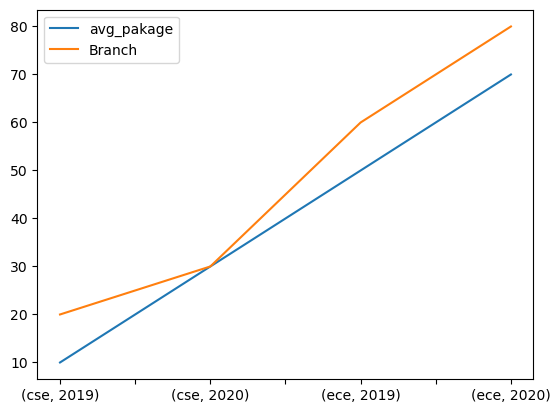

In [49]:
branch_df1.plot()

In [50]:
branch_df1.sort_index(level=1, ascending=False)

,,avg_pakage,Branch
ece,2020,70,80
cse,2020,30,30
ece,2019,50,60
cse,2019,10,20


In [51]:
branch_df1.transpose()

cse       ece     
           2019 2020 2019 2020
avg_pakage   10   30   50   70
Branch       20   30   60   80

In [54]:
branch_df1.swaplevel(axis=0)

,,avg_pakage,Branch
2019,cse,10,20
2020,cse,30,30
2019,ece,50,60
2020,ece,70,80


## Long vs Wide Data

(Practice Needed)

In [67]:
# Wide format: Single Row - Multipple Column
# Long format: Multi Row (As many as number of attributes)

In [82]:
ab = pd.DataFrame({'cse':[120],'ece':[130],'mech':[130]})
ab

,cse,ece,mech
0,120,130,130


In [71]:
# melt -> Wide to Long
ab.melt()

,variable,value
0,cse,120
1,ece,130
2,mech,130


In [80]:
# pivot -> Long to Wide
ab.melt().pivot(columns='variable', values='value')

variable,cse,ece,mech
0,120.0,NaN,NaN
1,NaN,130.0,NaN
2,NaN,NaN,130.0


# Pivot Table
 Takes simple column wise data as input and groups the entries into 2D table that provides Multi-dimensional summarization of the data.

In [83]:
import seaborn as sns

In [84]:
df = sns.load_dataset('tips')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [87]:
df.groupby('sex')[['total_bill','tip']].mean()

C:\Users\piyus\AppData\Local\Temp\ipykernel_10152\2240222177.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('sex')[['total_bill','tip']].mean()


,total_bill,tip
sex,,
Male,20.744076,3.089618
Female,18.056897,2.833448


In [95]:
df.pivot_table(index='sex',columns='smoker',values='total_bill',aggfunc='sum',margins=True)
# default aggfunc is mean

smoker,Yes,No,All
sex,,,
Male,1337.07,1919.75,3256.82
Female,593.27,977.68,1570.95
All,1930.34,2897.43,4827.77


In [94]:
df.pivot_table(index=['sex','smoker'],columns=['day','time'],aggfunc={'size':'mean','total_bill':'sum'})

size                                              \
day                Thur              Fri              Sat       Sun   
time              Lunch Dinner     Lunch Dinner    Dinner    Dinner   
sex    smoker                                                         
Male   Yes     2.300000    NaN  1.666667    2.4  2.629630  2.600000   
       No      2.500000    NaN       NaN    2.0  2.656250  2.883721   
Female Yes     2.428571    NaN  2.000000    2.0  2.200000  2.500000   
       No      2.500000    2.0  3.000000    2.0  2.307692  3.071429   

              total_bill                                                    
day                 Thur           Fri           Sat           Sun          
time               Lunch Dinner  Lunch  Dinner Lunch  Dinner Lunch  Dinner  
sex    smoker                                                               
Male   Yes        191.71   0.00  34.16  129.46   0.0  589.62   0.0  392.12  
       No         369.73   0.00   0.00   34.95   0.0  637.73   0.0  877.34  
Female Yes        134.53   0.00  39.78   48.80   0.0  304.00   0.0   66.16  
       No         381.58  18.78  15.98   22.75   0.0  247.05   0.0  291.54

# Strings

## Vecorized string operations

In [1]:
import numpy as np
import pandas as pd

In [2]:
# What are vecotorized operations?
a = np.array([1,2,3,4,5])
a * 4

array([ 4,  8, 12, 16, 20])

In [3]:
s= pd.Series(['cat','dog',None,'bird','horse'])
# string accessor
s.str.startswith('c')

0     True
1    False
2     None
3    False
4    False
dtype: object

In [37]:
# Import Dataset
df = pd.read_csv('D:\Machine Learning Notes\Pandas\B_energy_data.csv.csv')
df.head()

,Outdoor Temperature (°C),Building Area (sq ft),Name
0,22.8,11822,Rin
1,33.6,10992,Jin
2,18.6,7999,Tin King
3,22.8,11822,Kin
4,32.1,13857,Pin


### Common Functions

In [5]:
# lower/upper/capitalize/title
df['Name'].str.lower()        # All Lower
df['Name'].str.upper()        # All Upper
df['Name'].str.capitalize()   # First Word Capital
df['Name'].str.title()        # Every First Word Capital

0         Rin
1         Jin
2    Tin King
3         Kin
4         Pin
5        Fiin
6         Qin
7         Ain
Name: Name, dtype: object

In [6]:
# len
df['Name'].str.len().max()

8

In [7]:
# strip
df['Name'].str.strip()

0         Rin
1         Jin
2    Tin King
3         Kin
4         Pin
5        Fiin
6         Qin
7         Ain
Name: Name, dtype: object

In [8]:
# split -> get
df['FirstName'] = df['Name'].str.split(' ').str.get(0)
df.head()

,Outdoor Temperature (°C),Building Area (sq ft),Name,FirstName
0,22.8,11822,Rin,Rin
1,33.6,10992,Jin,Jin
2,18.6,7999,Tin King,Tin
3,22.8,11822,Kin,Kin
4,32.1,13857,Pin,Pin


In [9]:
df['Name'].str.split(' ').str.get(1).str.strip().str.split(' ', n=1, expand=True)

,0
0,NaN
1,NaN
2,King
3,NaN
4,NaN
5,NaN
6,NaN
7,NaN


In [10]:
df['Outdoor Temperature (°C)'].astype(str).str.split('.').str.get(0)    

0    22
1    33
2    18
3    22
4    32
5    15
6    22
7    20
Name: Outdoor Temperature (°C), dtype: object

In [11]:
df['Building Area (sq ft)'].value_counts()

Building Area (sq ft)
11822    2
10992    1
7999     1
13857    1
6478     1
8815     1
14896    1
Name: count, dtype: int64

In [12]:
df[df['Name'].str.startswith('R')]

,Outdoor Temperature (°C),Building Area (sq ft),Name,FirstName
0,22.8,11822,Rin,Rin


In [13]:
# Name that starts and ends with char vowel
df[df['FirstName'].str.contains('^[aeiouAEIOU].+[aeiouAEIOU]$')]

,Outdoor Temperature (°C),Building Area (sq ft),Name,FirstName


In [14]:
# Consonent
df[df['FirstName'].str.contains('^[^aeiouAEIOU].+[^aeiouAEIOU]$')]

,Outdoor Temperature (°C),Building Area (sq ft),Name,FirstName
0,22.8,11822,Rin,Rin
1,33.6,10992,Jin,Jin
2,18.6,7999,Tin King,Tin
3,22.8,11822,Kin,Kin
4,32.1,13857,Pin,Pin
5,15.8,6478,Fiin,Fiin
6,22.8,8815,Qin,Qin


In [15]:
# slicing
df['Name'].str[0::-1]

0    R
1    J
2    T
3    K
4    P
5    F
6    Q
7    A
Name: Name, dtype: object

## Timestamp Object
Time stamps reference particular moments in time (e.g., Oct 24th,2022 at 7:00pm)

#### Creating Timestamp Objects

In [16]:
# creating a timestamp
type(pd.Timestamp('2025/03/02'))

pandas._libs.tslibs.timestamps.Timestamp

In [19]:
# variations

# pd.Timestamp('2025-03-02')

pd.Timestamp('2025,03,02')

Timestamp('2025-02-01 00:00:00')

In [20]:
# only year
pd.Timestamp('2025')

Timestamp('2025-01-01 00:00:00')

In [21]:
# using text
pd.Timestamp('3th February 2025')

Timestamp('2025-02-03 00:00:00')

In [22]:
# providing time also
x = pd.Timestamp('2025-03-02 08:00:00')

In [23]:
x.year

2025

In [24]:
# using datetime format (Python Default)
import datetime as dt
dt.datetime(2025, 3, 2)

datetime.datetime(2025, 3, 2, 0, 0)

In [25]:
# why separate objects to handle data and time when python already has datetime functionality?

-> Performance takes hit while working with huge data

In [26]:
# Collection of timestamp object
pd.DatetimeIndex(['2030-01-01', '2030-01-02', '2030-01-03'])[0]

Timestamp('2030-01-01 00:00:00')

In [27]:
# Or
pd.DatetimeIndex([dt.datetime(2030, 1, 1), dt.datetime(2030, 1, 2), dt.datetime(2030, 1, 3)])[0]

Timestamp('2030-01-01 00:00:00')

### date_range Function

In [28]:
pd.date_range(start='2025-01-01', end='2025-01-10', freq='2D')

DatetimeIndex(['2025-01-01', '2025-01-03', '2025-01-05', '2025-01-07',
               '2025-01-09'],
              dtype='datetime64[ns]', freq='2D')

In [29]:
# W -> one week per day
pd.date_range(start='2025-01-01', end='2025-01-02', freq='6H')
# Insted of end use periods if we want to generate new data.

DatetimeIndex(['2025-01-01 00:00:00', '2025-01-01 06:00:00',
               '2025-01-01 12:00:00', '2025-01-01 18:00:00',
               '2025-01-02 00:00:00'],
              dtype='datetime64[ns]', freq='6H')

## to_datetime And .dt Function

converts an existing object to datetimeindex object/ pandas timestamp

In [32]:
# simple series example
s = pd.Series(['2023/1/1', '2023/2/1', '2023/3/1'])
s

0    2023/1/1
1    2023/2/1
2    2023/3/1
dtype: object

In [33]:
# Directly accessing the year
s.str.split('/').str.get(0)

0    2023
1    2023
2    2023
dtype: object

In [34]:
# Better Way
pd.to_datetime(s)

0   2023-01-01
1   2023-02-01
2   2023-03-01
dtype: datetime64[ns]

In [35]:
pd.to_datetime(s).dt.year

0    2023
1    2023
2    2023
dtype: int32

In [42]:
# With errors
s = pd.Series(['2023/1/1', '2023/2/1', '2023/103/1'])
pd.to_datetime(s, errors='coerce')

0   2023-01-01
1   2023-02-01
2          NaT
dtype: datetime64[ns]

## Resampling

Resampling involves changing the frequency of your time series observations

Two types of resampling:

Unsampling: Where you increase the frequency of the sample, such as from minutes to seconds

Downsampling: Where you decrease the frequency of the sample, such as from days to months

Original DataFrame:
               Value
2023-01-01  2.004749
2023-01-02 -0.039436
2023-01-03  0.648666
2023-01-04 -0.472801
2023-01-05 -1.060015
2023-01-06  0.169217
2023-01-07 -0.312027
2023-01-08  0.391225
2023-01-09 -0.769787
2023-01-10 -0.759388


<Axes: >

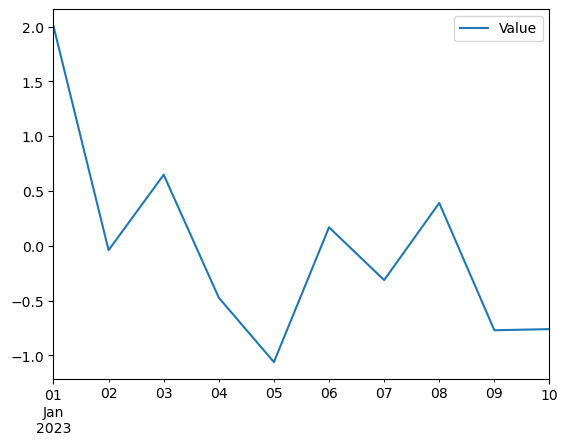

In [53]:
# Creating a time series DataFrame
date_range = pd.date_range(start='2023-01-01', end='2023-01-10', freq='D')
data = np.random.randn(len(date_range))
df = pd.DataFrame(data, index=date_range, columns=['Value'])

# Original DataFrame
print("Original DataFrame:")
print(df)
df.plot()


Downsampled DataFrame (Weekly):
               Value
2023-01-01  2.004749
2023-01-08 -0.096453
2023-01-15 -0.764588


<Axes: >

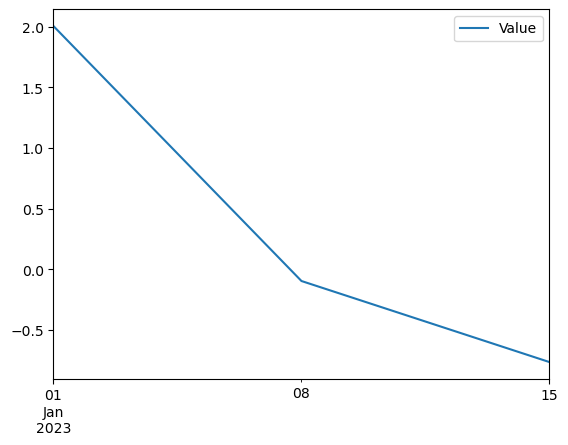

In [54]:
# Downsampling: Converting daily data to weekly data
df_downsampled = df.resample('W').mean()
print("\nDownsampled DataFrame (Weekly):")
print(df_downsampled)
df_downsampled.plot()


Upsampled DataFrame (Hourly):
                        Value
2023-01-01 00:00:00  2.004749
2023-01-01 01:00:00  1.251524
2023-01-01 02:00:00  1.229026
2023-01-01 03:00:00  1.206670
2023-01-01 04:00:00  1.184454
...                       ...
2023-01-09 20:00:00 -0.368473
2023-01-09 21:00:00 -0.361189
2023-01-09 22:00:00 -0.353764
2023-01-09 23:00:00 -0.346199
2023-01-10 00:00:00 -0.759388

[217 rows x 1 columns]


<Axes: >

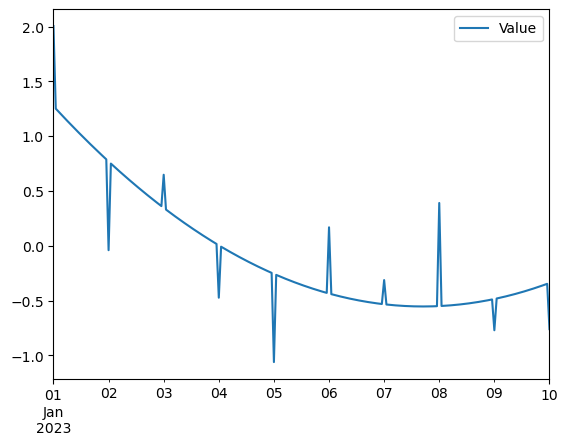

In [70]:
# Upsampling: Converting daily data to hourly data (Not used much)
df_upsampled = df.resample('H').interpolate(method='spline',order = 2)
print("\nUpsampled DataFrame (Hourly):")
print(df_upsampled)
df_upsampled.plot()

## Rolling Window (Smoothing)

Time series data in the original format can be quite volatile, especially on smaller aggregation levels. The concept of rolling, or moving average is useful technique for smoothing time series data.


DataFrame with Moving Average (3-day window):
               Value  Moving_Avg
2023-01-01  2.004749         NaN
2023-01-02 -0.039436         NaN
2023-01-03  0.648666    0.871326
2023-01-04 -0.472801    0.045476
2023-01-05 -1.060015   -0.294717
2023-01-06  0.169217   -0.454533
2023-01-07 -0.312027   -0.400942
2023-01-08  0.391225    0.082805
2023-01-09 -0.769787   -0.230196
2023-01-10 -0.759388   -0.379317


<Axes: >

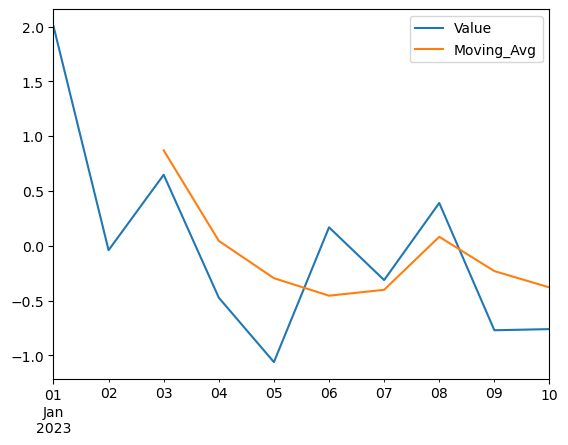

In [72]:
# Rolling Window (Smoothing)
# Calculating the moving average with a window of 3 days
df['Moving_Avg'] = df['Value'].rolling(window=3).mean()
print("\nDataFrame with Moving Average (3-day window):")
print(df)
df.plot()

## Shifting 

The shift() function is used to shift the entire series up or down by the desired number of periods.


DataFrame with Previous Day Value:
               Value  Moving_Avg  Prev_Day_Value
2023-01-01  2.004749         NaN             NaN
2023-01-02 -0.039436         NaN        2.004749
2023-01-03  0.648666    0.871326       -0.039436
2023-01-04 -0.472801    0.045476        0.648666
2023-01-05 -1.060015   -0.294717       -0.472801
2023-01-06  0.169217   -0.454533       -1.060015
2023-01-07 -0.312027   -0.400942        0.169217
2023-01-08  0.391225    0.082805       -0.312027
2023-01-09 -0.769787   -0.230196        0.391225
2023-01-10 -0.759388   -0.379317       -0.769787


<Axes: >

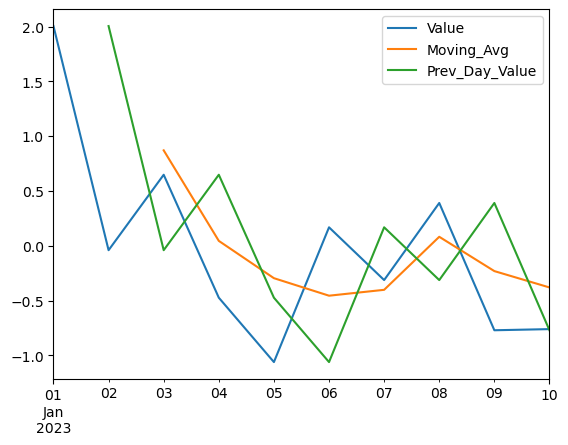

In [74]:
# shift
df['Prev_Day_Value'] = df['Value'].shift(1)
print("\nDataFrame with Previous Day Value:")
print(df)
df.plot()